# Looking at the outcome of spike sorting

In [14]:
session_dir = "../data/birds/GreYel3594M/GreYel3594M___170915_125724"

In [2]:
bird, session = session_dir.split("/")[-2:]

In [3]:
import cPickle as pickle
import matplotlib.pyplot as plt
import numpy as np
import os

from segment_analysis import MultiSegment

import config

/auto/fhome/kevin/Projects/songephys/env/local/lib/python2.7/site-packages/h5py/__init__.py:34: FutureWarning: Conversion of the second argument of issubdtype from `float` to `np.floating` is deprecated. In future, it will be treated as `np.float64 == np.dtype(float).type`.
  from ._conv import register_converters as _register_converters


In [6]:
from ipywidgets import interact, widgets
%matplotlib notebook

In [75]:
data_path = os.path.join(session_dir, "spikes", "{}-sorted-resegmented.pkl").format(session)

In [76]:
with open(data_path, "rb") as datafile:
    block = pickle.load(datafile)

In [77]:
multiseg = MultiSegment(block.segments)

<IPython.core.display.Javascript object>


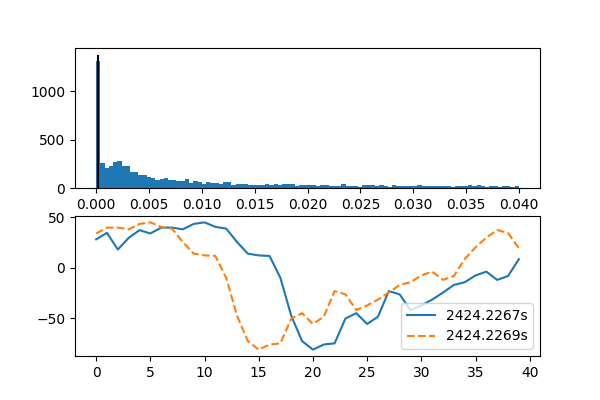

interactive(children=(Dropdown(description=u'Electrode:', options=(('Amp Elec 5', <neo.core.channelindex.ChannelIndex object at 0x7fc40168ee90>), ('Amp Elec 6', <neo.core.channelindex.ChannelIndex object at 0x7fc40168ebd0>), ('Amp Elec 10', <neo.core.channelindex.ChannelIndex object at 0x7fc3ff689510>), ('Amp Elec 11', <neo.core.channelindex.ChannelIndex object at 0x7fc3ff689a10>), ('Amp Elec 12', <neo.core.channelindex.ChannelIndex object at 0x7fc3ff689a50>)), value=<neo.core.channelindex.ChannelIndex object at 0x7fc40168ee90>), Output()), _dom_classes=('widget-interact',))

interactive(children=(Dropdown(description=u'Unit:', index=1, options=(('--', None), ('e5u0', <neo.core.unit.Unit object at 0x7fc40168ef50>)), value=<neo.core.unit.Unit object at 0x7fc40168ef50>), FloatText(value=0.001, description=u'threshold'), SelectionSlider(continuous_update=False, description=u'Spike ID', options=(0,), value=0), Output()), _dom_classes=('widget-interact',))

In [107]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6, 4))

electrode_dropdown = widgets.Dropdown(
    options=[(c.name, c) for c in block.channel_indexes[:-1]],
    value=block.channel_indexes[0],
    description='Electrode:',
    disabled=False,
)

unit_dropdown = widgets.Dropdown(
    options=[("--", None)] + [(e.name, e) for e in electrode_dropdown.value.units],
    value=electrode_dropdown.value.units[0],
    description='Unit:',
    disabled=False,
)

spike_selector = widgets.SelectionSlider(
    options=[0],
    value=0,
    description="Spike ID",
    continuous_update=False,
)

violation_threshold_box = widgets.FloatText(value=0.001)

def select_electrode(elec):
    for ax in axes:
        ax.clear()
    unit_dropdown.options = [("--", None)] + [(e.name, e) for e in elec.units]
    
def select_unit(u, threshold, spike_idx):
    if u is None:
        return
    for ax in axes:
        ax.clear()
    elec = electrode_dropdown.value
    unit = unit_dropdown.value
    
    times = np.concatenate([st.times for st in unit.spiketrains])
    unit_idx_lookup = np.concatenate([(np.ones(len(st.times)) * i).astype(int) for i, st in enumerate(unit.spiketrains) ])
    spikes = np.concatenate([st.waveforms for st in unit.spiketrains if len(st.waveforms)])
    times = times.as_array()
    
    sorter = np.argsort(times)
    times = times[sorter]
    unit_idx_lookup = unit_idx_lookup[sorter]
    spikes = spikes[sorter]
    
    violations = np.where((
        (np.abs(np.diff(times)) < violation_threshold_box.value) &
        (np.abs(np.diff(times)) != 0.0)
    ))[0]
    
    if not len(violations):
        axes[1].text(20, 0, "No violations in this range")
        return
    
    idx1 = violations[spike_selector.value]
    idx2 = violations[spike_selector.value] + 1
    seg1 = unit_idx_lookup[idx1]
    seg2 = unit_idx_lookup[idx2]
    spike_selector.options = range(len(violations))
    axes[1].plot(spikes[violations[spike_selector.value]], label="{:.4f}s".format(times[idx1]))
    axes[1].plot(spikes[violations[spike_selector.value] + 1], linestyle="--", label="{:.4f}s".format(times[idx2]))
    axes[1].legend(loc="lower right")
    
    axes[0].hist(np.diff(times), bins=100, range=(0, 0.04))
    axes[0].vlines([violation_threshold_box.value], *axes[0].get_ylim())
    fig.canvas.draw()
        
display(widgets.interactive(select_electrode, elec=electrode_dropdown))
display(widgets.interactive(select_unit, u=unit_dropdown, threshold=violation_threshold_box, spike_idx=spike_selector))
